In [ ]:
#Bài làm mẫu 2 — Nhận diện chữ viết tay MNIST
#Tìm hiểu cách biểu diễn và hiển thị ảnh

In [ ]:
"""Máy tính không trực tiếp hiểu một hình ảnh như con người. Ta chuyển ảnh thành mảng số:
- Dạng ảnh: (28, 28).
- Dạng đầu vào cho SVM: (784,), tức một vector gồm 784 đặc trưng.
- Nhãn: một số nguyên từ 0 đến 9.
Ví dụ, mỗi pixel là một đặc trưng và cường độ sáng của nó là giá trị đầu vào. Khi dùng SVM, ta thường đưa giá trị pixel về khoảng 0–1."""

In [ ]:
#Nhiệm vụ 2: Xây dựng mô hình SVM

In [ ]:
#Tải dữ liệu MNIST

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [3]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="auto"
)

X_mnist = mnist.data.astype(np.float32)
y_mnist = mnist.target.astype(np.int64)

print("Kích thước ảnh sau khi làm phẳng:", X_mnist.shape)
print("Kích thước nhãn:", y_mnist.shape)
print("Các nhãn:", np.unique(y_mnist))

Kích thước ảnh sau khi làm phẳng: (70000, 784)
Kích thước nhãn: (70000,)
Các nhãn: [0 1 2 3 4 5 6 7 8 9]


In [4]:
#Hiển thị một số ảnh

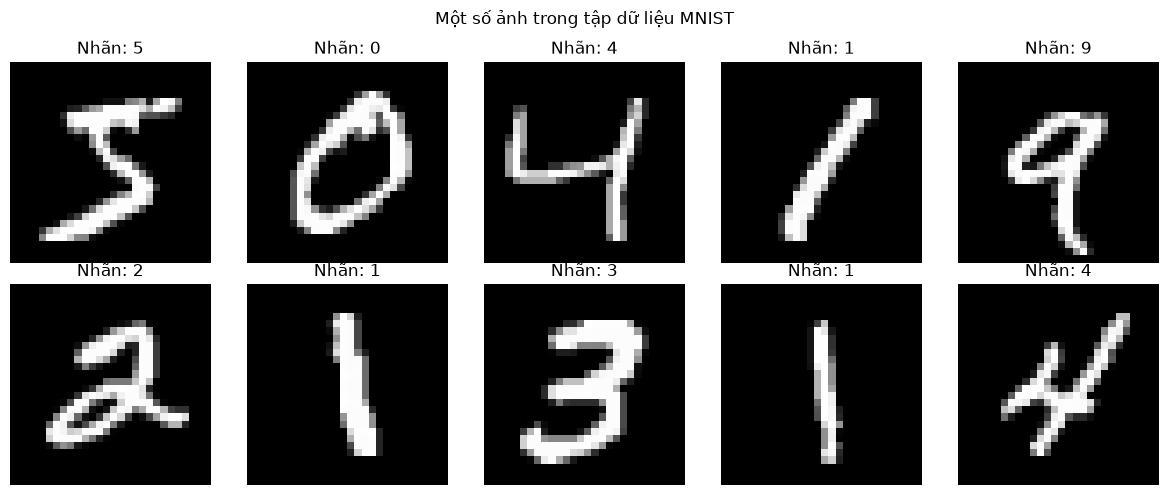

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_mnist[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Nhãn: {y_mnist[i]}")
    ax.axis("off")

plt.suptitle("Một số ảnh trong tập dữ liệu MNIST")
plt.tight_layout()
plt.show()

In [6]:
#Chuẩn hóa dữ liệu và chia tập

In [7]:
from sklearn.model_selection import train_test_split

# Chọn 12.000 mẫu để thử nghiệm nhanh hơn
X_subset, _, y_subset, _ = train_test_split(
    X_mnist,
    y_mnist,
    train_size=12000,
    random_state=42,
    stratify=y_mnist
)

X_train_mnist, X_test_mnist, y_train_mnist, y_test_mnist = (
    train_test_split(
        X_subset,
        y_subset,
        test_size=0.2,
        random_state=42,
        stratify=y_subset
    )
)

# Giá trị pixel gốc thường nằm trong khoảng 0–255
X_train_mnist = X_train_mnist / 255.0
X_test_mnist = X_test_mnist / 255.0

print("Train:", X_train_mnist.shape)
print("Test:", X_test_mnist.shape)

Train: (9600, 784)
Test: (2400, 784)


In [8]:
#Huấn luyện SVM

In [9]:
import time

svm_mnist = SVC(
    kernel="rbf",
    C=5.0,
    gamma="scale"
)

start = time.time()
svm_mnist.fit(X_train_mnist, y_train_mnist)
train_time = time.time() - start

print(f"Thời gian huấn luyện: {train_time:.2f} giây")

Thời gian huấn luyện: 19.98 giây


In [ ]:
#Đánh giá mô hình

In [10]:
y_pred_mnist = svm_mnist.predict(X_test_mnist)

print(
    "Accuracy:",
    round(accuracy_score(y_test_mnist, y_pred_mnist), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_test_mnist,
    y_pred_mnist,
    labels=list(range(10)),
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mnist,
    y_pred_mnist,
    labels=list(range(10)),
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — SVM trên MNIST")
plt.show()

Accuracy: 0.9679

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       237
           1       0.98      1.00      0.99       270
           2       0.97      0.95      0.96       240
           3       0.98      0.97      0.98       245
           4       0.94      0.95      0.95       234
           5       0.97      0.98      0.97       216
           6       0.96      0.98      0.97       236
           7       0.98      0.97      0.97       250
           8       0.95      0.97      0.96       234
           9       0.95      0.93      0.94       238

    accuracy                           0.97      2400
   macro avg       0.97      0.97      0.97      2400
weighted avg       0.97      0.97      0.97      2400



NameError: name 'ConfusionMatrixDisplay' is not defined

In [ ]:
#Hiển thị dự đoán trên ảnh

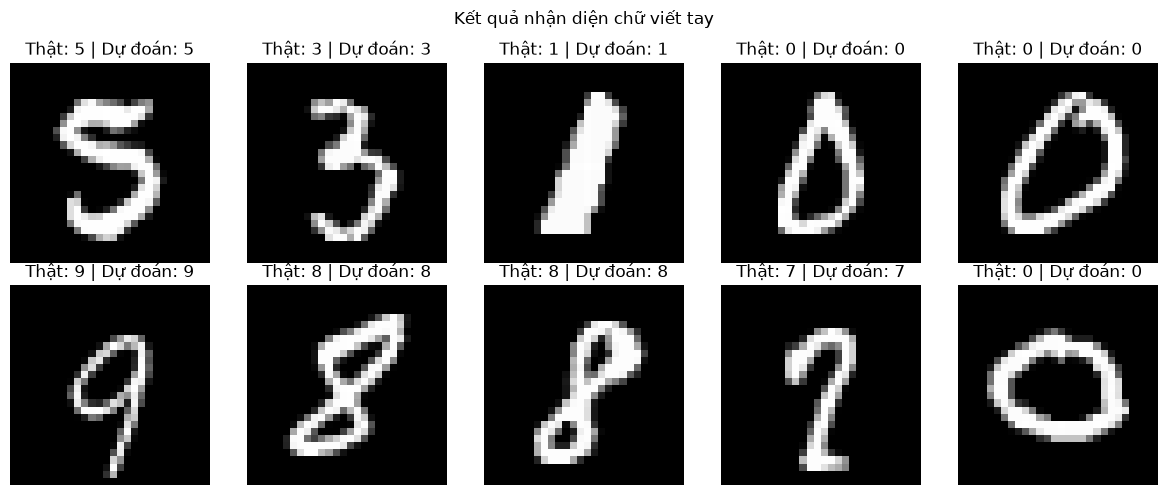

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = X_test_mnist[i].reshape(28, 28)
    actual = y_test_mnist[i]
    predicted = y_pred_mnist[i]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Thật: {actual} | Dự đoán: {predicted}")
    ax.axis("off")

plt.suptitle("Kết quả nhận diện chữ viết tay")
plt.tight_layout()
plt.show()